1. download CIFAR-10
2. implement CNN
3. Loss, hyperparameters

In [27]:
# !tar -xzf cifar-10-python.tar.gz

In [ ]:
import os
print(os.getcwd()) 
DATA_PATH = "/kaggle/input/datasets/avezorgen/cifar10-orig/cifar-10-batches-py/"

d:\code\notebooks\deep-learning-course-practice-2026\laboratory_work_2


In [11]:
def unpickle(file):
    import pickle
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

data = unpickle(f'{DATA_PATH}/data_batch_1')

C:\Users\User\AppData\Local\Temp\ipykernel_14704\1729856436.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


In [12]:
for k, v in data.items():
    if k == b'batch_label':
        print(k, v)
        continue
    print(k, len(v))

b'batch_label' b'training batch 1 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000


In [14]:
import os
batch_names = ('data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5')
for b in batch_names:
    data = unpickle(os.path.join(DATA_PATH, b))
    print(b)
    for k, v in data.items():
        if k == b'batch_label':
            print(k, v)
        else:
            print(k, len(v))
    

data_batch_1
b'batch_label' b'training batch 1 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_2
b'batch_label' b'training batch 2 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_3
b'batch_label' b'training batch 3 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_4
b'batch_label' b'training batch 4 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_5
b'batch_label' b'training batch 5 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000


C:\Users\User\AppData\Local\Temp\ipykernel_14704\1729856436.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


In [15]:
data[b'labels'][0], data[b'filenames'][0], data[b'data'][0]

(1,
 b'compact_car_s_001706.png',
 array([255, 252, 253, ..., 173, 231, 248], shape=(3072,), dtype=uint8))

In [16]:
meta = unpickle(f'{DATA_PATH}/batches.meta')
for k, v in meta.items():
    print(k, v)

b'num_cases_per_batch' 10000
b'label_names' [b'airplane', b'automobile', b'bird', b'cat', b'deer', b'dog', b'frog', b'horse', b'ship', b'truck']
b'num_vis' 3072


In [ ]:
import random
import numpy as np
import torch

config = {
    "seed": 42,
    "batch_size": 128,
    "zoom_scale": (0.9, 1.1),
    "zoom_probability": 0.5,
    "num_epochs": 90,
    "learning_rate": 0.1,
    "warmup_learning_rate": 0.01,
    "warmup_error_threshold": 0.8,
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "min_learning_rate": 1e-4,
}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(config["seed"])
for name, value in config.items():
    print(f"{name}: {value}")

In [18]:
import os
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2


class CIFAR10Dataset(Dataset):
    def __init__(self, batch_names, transform=None):
        batches = [unpickle(name) for name in batch_names]

        self.images = torch.from_numpy(
            np.concatenate([batch[b"data"] for batch in batches])
        ).reshape(-1, 3, 32, 32)
        self.labels = torch.as_tensor(
            np.concatenate([batch[b"labels"] for batch in batches]),
            dtype=torch.long,
        )
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        if self.transform is not None:
            image = self.transform(image)
        return image, self.labels[index]


train_dataset = CIFAR10Dataset(
    [os.path.join(DATA_PATH, f"data_batch_{i}") for i in range(1, 6)]
)

num_classes = len(meta[b"label_names"])

scaled_images = train_dataset.images.to(torch.float32) / 255
channel_mean = scaled_images.mean(dim=(0, 2, 3))
channel_std = scaled_images.std(dim=(0, 2, 3), correction=0)
del scaled_images

train_transform = v2.Compose(
    [
        v2.RandomCrop(32, padding=4),
        v2.RandomHorizontalFlip(),
        v2.ToDtype(torch.float32, scale=True),
        # v2.RandomApply([
        #     v2.RandomAffine(
        #         degrees=0,
        #         scale=config["zoom_scale"],
        #         interpolation=v2.InterpolationMode.BILINEAR,
        #         fill=tuple(channel_mean.tolist()),
        #     ),
        # ], p=config["zoom_probability"]),
        v2.Normalize(mean=channel_mean.tolist(), std=channel_std.tolist()),
    ]
)
test_transform = v2.Compose(
    [
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize(mean=channel_mean.tolist(), std=channel_std.tolist()),
    ]
)
train_dataset.transform = train_transform
test_dataset = CIFAR10Dataset(
    [os.path.join(DATA_PATH, "test_batch")], transform=test_transform
)
print("Normalization mean:", channel_mean.tolist())
print("Normalization std:", channel_std.tolist())

C:\Users\User\AppData\Local\Temp\ipykernel_14704\1729856436.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


Normalization mean: [0.491400808095932, 0.48215898871421814, 0.44653093814849854]
Normalization std: [0.24703224003314972, 0.24348513782024384, 0.26158785820007324]


Train
	Total: torch.Size([50000, 3, 32, 32]); labels: torch.Size([50000])
	One item: torch.Size([3, 32, 32]), torch.float32; label: torch.Size([]), torch.int64
Test
	Total: torch.Size([10000, 3, 32, 32]); labels: torch.Size([10000])
	One item: torch.Size([3, 32, 32]), torch.float32; label: torch.Size([]), torch.int64


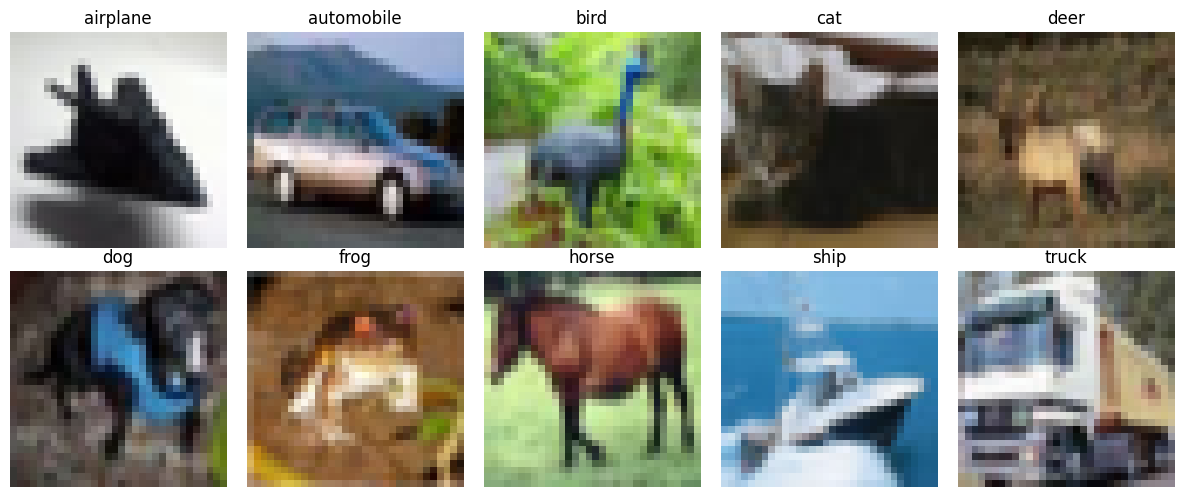

In [19]:
import matplotlib.pyplot as plt

for name, dataset in (("Train", train_dataset), ("Test", test_dataset)):
    image, label = dataset[0]
    print(name)
    print(f"\tTotal: {dataset.images.shape}; labels: {dataset.labels.shape}")
    print(f"\tOne item: {image.shape}, {image.dtype}; label: {label.shape}, {label.dtype}")

class_names = [name.decode("utf-8") for name in meta[b"label_names"]]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    index = (train_dataset.labels == class_id).nonzero(as_tuple=True)[0][0].item()
    image = train_dataset.images[index]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

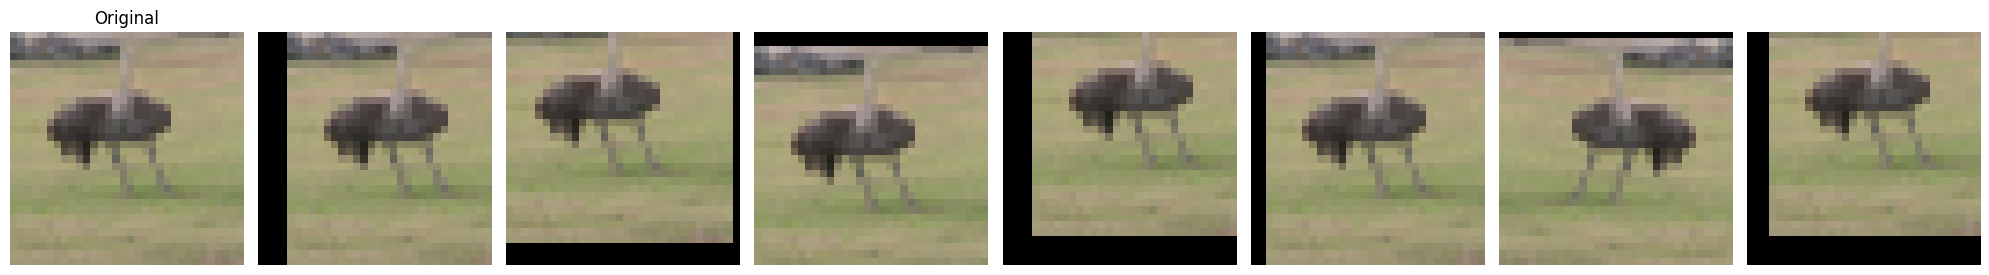

In [20]:
sample_index = 42
original_image = train_dataset.images[sample_index]
sample_label = train_dataset.labels[sample_index].item()

fig, axes = plt.subplots(1, 8, figsize=(20, 5))
axes = axes.ravel()
axes[0].imshow(original_image.permute(1, 2, 0), interpolation="nearest")
axes[0].set_title("Original")

for number, axis in enumerate(axes[1:8], start=1):
    transformed_image, label = train_dataset[sample_index]
    display_image = (
        transformed_image * channel_std.reshape(-1, 1, 1)
        + channel_mean.reshape(-1, 1, 1)
    ).clamp(0, 1)

    axis.imshow(display_image.permute(1, 2, 0), interpolation="nearest")

for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

In [21]:
train_generator = torch.Generator().manual_seed(config["seed"])
train_loader = DataLoader(
    train_dataset,
    batch_size=config["batch_size"],
    shuffle=True,
    generator=train_generator,
)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

In [22]:
import numpy as np
# rng = np.random.default_rng(0)
# AlexNet, VGG, GoogLeNet, ResNet
class ConvolutionalNeuralNetwork(torch.nn.Module):
    def __init__(self):
        super(ConvolutionalNeuralNetwork, self).__init__()
        # Свертка. Размер результирующей карты признаков:
        # 10 x ((28-3)/1+1) x ((28-3)/1+1) = 10 x 26 x 26
        self.conv = torch.nn.Conv2d(
            in_channels = 3, out_channels = 10, kernel_size = 3, stride = 1
        )
        # Функция активации. Размер результирующей карты признаков:
        # 10 x 26 x 26
        self.activation = torch.nn.ReLU()
        # Пространственное объединение по максимуму. Размер результирующей карты признаков:
        # 10 x ((26-2)/1+1) x ((26-2)/1+1) = 10 x 25 x 25
        self.pooling = torch.nn.MaxPool2d(kernel_size = 2, stride = 1)
        # Создание полносвязного слоя (softmax включается в вычисление кросс-энтропии)
        self.linear = torch.nn.Linear(10 * 29 * 29, 10)

        # torch.nn.init.dirac(self.conv.weight)
        # torch.nn.init.xavier_normal_(self.linear.weight, gain=torch.nn.init.calculate_gain("relu"))


    
    def forward(self, x):
        out = self.conv(x)
        out = self.activation(out)
        out = self.pooling(out)
        # Изменение формата хранения тензора из (B, C, W, H) в (B, C*W*H)
        out = out.view(out.size(0), -1)
        # print(out.shape)
        out = self.linear(out)
        return out # softmax содержится внутри cross-entropy 

cnn_model = ConvolutionalNeuralNetwork()

# batch size, channels, width, height
cnn_model(torch.rand(1, 3, 32, 32)) 
cnn_model

ConvolutionalNeuralNetwork(
  (conv): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
  (activation): ReLU()
  (pooling): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (linear): Linear(in_features=8410, out_features=10, bias=True)
)

In [ ]:
import torch.nn as nn


# https://www.kaggle.com/code/spellsharp/resnets-an-intuitive-approach
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            stride=stride,
            padding=1,
            kernel_size=3,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            stride=1,
            padding=1,
            kernel_size=3,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)  # NOTE: MYEDIT
        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


def make_layer(in_channels, out_channels, stride=1):
    downsample = None
    if stride != 1 or in_channels != out_channels:
        downsample = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, kernel_size=1, stride=stride, bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )
    return nn.Sequential(
        ResidualBlock(in_channels, out_channels, stride=stride, downsample=downsample),
        ResidualBlock(out_channels, out_channels),
    )


class ResNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(
            3, 16, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(16)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = make_layer(in_channels=16, out_channels=16, stride=1)
        self.layer2 = make_layer(in_channels=16, out_channels=32, stride=2) # w downsample
        self.layer3 = make_layer(in_channels=32, out_channels=64, stride=2) # w downsample
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(in_features=64, out_features=num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x

In [ ]:
cnn_model = ResNet(num_classes=num_classes)
num_blocks = len(cnn_model.layer1) + len(cnn_model.layer2) + len(cnn_model.layer3)
main_path_layers = 2 + 2 * num_blocks
print(f"Main-path convolutional + linear layers: {main_path_layers}")
print(f"Parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")
print(cnn_model)

In [25]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [26]:
import time

loss_function = torch.nn.CrossEntropyLoss()


def run_epoch(model, data_loader, optimizer=None):
    training = optimizer is not None
    was_training = model.training
    model.train(training)
    running_loss, correct, n = 0.0, 0, 0
    try:
        with torch.set_grad_enabled(training):
            for images, labels in data_loader:
                images, labels = images.to(device), labels.to(device)
                if training:
                    optimizer.zero_grad()
                outputs = model(images)
                loss = loss_function(outputs, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                batch_size = labels.size(0)
                n += batch_size
                running_loss += loss.item() * batch_size
                correct += (outputs.argmax(1) == labels).sum().item()
    finally:
        model.train(was_training)
    return {"loss": running_loss / n, "accuracy": correct / n}


def get_accuracy(data_loader, model):
    result = run_epoch(model, data_loader)
    return result["accuracy"], result["loss"]

In [ ]:
set_seed(config["seed"])
train_generator.manual_seed(config["seed"])
cnn_model = ResNet(num_classes=num_classes).to(device)
optimizer = torch.optim.SGD(
    cnn_model.parameters(), lr=config["warmup_learning_rate"],
    momentum=config["momentum"], weight_decay=config["weight_decay"],
)
scheduler = None
metrics = []
for epoch in range(config["num_epochs"]):
    started = time.perf_counter()
    epoch_learning_rate = optimizer.param_groups[0]["lr"]
    train_result = run_epoch(cnn_model, train_loader, optimizer)
    test_accuracy, test_loss = get_accuracy(test_loader, cnn_model)
    metrics.append({
        "epoch": epoch + 1,
        "train_loss": train_result["loss"], "train_accuracy": train_result["accuracy"],
        "test_loss": test_loss, "test_accuracy": test_accuracy,
        "learning_rate": epoch_learning_rate,
    })
    if scheduler is not None:
        scheduler.step()
    elif 1 - train_result["accuracy"] < config["warmup_error_threshold"]:
        remaining_epochs = config["num_epochs"] - epoch - 1
        if remaining_epochs:
            optimizer.param_groups[0]["lr"] = config["learning_rate"]
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                optimizer, T_max=remaining_epochs, eta_min=config["min_learning_rate"]
            )
    print(
        f"Epoch[{epoch + 1}/{config['num_epochs']}]: lr={epoch_learning_rate:.5f} "
        f"train_loss={train_result['loss']:.4f} train_accuracy={train_result['accuracy']:.4f} "
        f"test_loss={test_loss:.4f} test_accuracy={test_accuracy:.4f} "
        f"elapsed={time.perf_counter() - started:.1f}s", flush=True,
    )
cnn_model.eval();

In [ ]:
test_loss = metrics[-1]["test_loss"]
test_accuracy = metrics[-1]["test_accuracy"]
print(f"Test loss = {test_loss:.4f}; Test accuracy = {test_accuracy:.4f} ({test_accuracy:.2%})")

In [ ]:
metrics[-1]

In [ ]:
epochs = [m["epoch"] for m in metrics]
fig, ax = plt.subplots(1, 2, figsize=(25, 6))

ax[0].plot(epochs, [m["train_loss"] for m in metrics], label="Train Loss", color="royalblue", linewidth=2)
ax[0].plot(epochs, [m["test_loss"] for m in metrics], label="Test Loss", color="darkorange", linewidth=2)
ax[0].set_title("Model Loss Progression", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Epoch", fontsize=12)
ax[0].set_ylabel("Loss", fontsize=12)
ax[0].grid(True, linestyle="--", alpha=0.6)
ax[0].legend(fontsize=11)

ax[1].plot(epochs, [100 * m["train_accuracy"] for m in metrics], label="Train Accuracy", color="royalblue", linewidth=2)
ax[1].plot(epochs, [100 * m["test_accuracy"] for m in metrics], label="Test Accuracy", color="darkorange", linewidth=2)
ax[1].set_title("Model Accuracy Progression", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Epoch", fontsize=12)
ax[1].set_ylabel("Accuracy (%)", fontsize=12)
ax[1].grid(True, linestyle="--", alpha=0.6)
ax[1].legend(fontsize=11)

for axis in ax:
    axis.set_xticks(list(epochs))
ax[0].tick_params(axis="x", labelrotation=45)
ax[1].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

In [ ]:
epochs = [m["epoch"] for m in metrics]
learning_rates = [m["learning_rate"] for m in metrics]

fig, lr_ax = plt.subplots(figsize=(12, 6))
lr_ax.plot(epochs, learning_rates)
lr_ax.set_xlabel("Epoch")
lr_ax.set_ylabel("Learning rate")
lr_ax.grid(True, linestyle="--", alpha=0.6)
fig.tight_layout()
plt.show()